# Geospatial Data · Part 1: Earthquakes, Spatial Indexing & Classical Geo-ML (`vkspatial`)

Every dataset so far lived in flat tables, pixel grids, word spaces, timelines, or abstract graphs. **Geospatial data** lives on the **curved surface of the Earth** — every point has a `(latitude, longitude)` (and often an altitude or depth).

### Why Geospatial Data Breaks Naive Flat Math
If you treat `(longitude, latitude)` like a normal flat `(x, y)` chart, two things immediately go wrong:
1. **The ±180° Pacific Wrap (Antimeridian):** Fiji (`+178°E`) and Tonga (`-175°W`) are only **~780 km** apart across the Pacific — yet flat math thinks they are `353°` apart on opposite sides of the planet!
2. **Shrinking Longitude Lines:** `1°` of longitude is **111 km** wide at the Equator, but only **~55 km** wide in Alaska (`60°N`) and **0 km** at the North Pole.

To handle Earth properly, geospatial engines use **Haversine great-circle distance**, **3D unit-sphere coordinates** `(x, y, z)`, **Morton Z-order spatial indexes**, and **density clustering (`DBSCAN`)**.

> **Real-World Geospatial AI & Who Uses It:**
> | Algorithm / Tool | What It Solves | Used By |
> |---|---|---|
> | **Spatial Indexes (`Morton Z-Order`, `H3`, `S2`)** | Find all nearby drivers, stores, or quakes in milliseconds | **Uber (`H3`)**, **Google Maps (`S2`)**, **PostGIS**, **NVIDIA `cuSpatial`** |
> | **Haversine / Great-Circle Distance** | True shortest distance along Earth's curved surface | **DoorDash**, **Airbnb**, **FlightRadar24** |
> | **Density Clustering (`DBSCAN`)** | Discover organic hotspots & fault lines without picking `k` clusters | **USGS**, **Insurance Risk Modeling**, **Ride-Share Surge Zones** |
> | **Spatial Features + Tree Ensembles (`GBDT`/`RF`)** | Predict hazard severity, ETA, or local demand | **NOAA**, **Zillow**, **Waymo** |


In [1]:
import math, sys, time
from pathlib import Path
from IPython.display import display

_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import vknumpy as vnp
import vkpandas as vpd
import vkspatial as vksp
import vklearn as vkl
import vkvis
import vkplot

print(f"Vulkan GPU ready: {vnp.device_info()['name']}")

# 1. Load real USGS Global Earthquakes (M >= 2.5, past 30 days) in 1 line!
df, gdf = vksp.load_earthquakes()
display(df.head(5))
display(df.describe())

# Target: Significant Earthquake (M >= 4.5, felt widely & tracked for hazard response)
y_sig = (df["mag"]._data >= 4.5)
n_sig = int(vnp.sum(y_sig))
print(f"Loaded {len(df):,} real USGS global earthquakes | Significant (M >= 4.5): {n_sig:,} ({n_sig/len(df):.1%})")
print(f"Magnitude range: {df['mag'].min():.2f} to {df['mag'].max():.2f} | Max depth: {df['depth'].max():.1f} km")


Vulkan GPU ready: AMD Custom GPU 0405 (RADV VANGOGH)


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


#,latitude,longitude,depth,mag,rms,place,mag_type
0,61.918,-149.96,5.6,3.3,1.4,"19 km NNE of Willow, Alaska",ml
1,18.174,-68.702,74,3.58,0.44,"24 km SSW of Boca de Yuma, Dominican Republic",md
2,62.139,-149.591,56.2,2.8,0.8,"13 km E of Susitna North, Alaska",ml
3,59.285,-152.491,64.5,3,0.7,"33 km WSW of Nanwalek, Alaska",ml
4,18.986,-156.265,45.74,2.6,0.14,"53 km W of Hawaiian Ocean View, Hawaii",ml


'vkpandas.DataFrame (1,763 rows x 7 columns)\n  latitude  | min=    -63.09  mean=     25.15  std=    31.38  max=     86.72  NaNs=0\n  longitude | min=   -179.98  mean=    -43.69  std=   127.41  max=    179.99  NaNs=0\n  depth     | min=      0.00  mean=     62.38  std=   116.42  max=    651.66  NaNs=0\n  mag       | min=      2.45  mean=      3.73  std=     0.94  max=      6.80  NaNs=0\n  rms       | min=      0.04  mean=      0.63  std=     0.29  max=      1.81  NaNs=0\n  place     | CATEGORICAL (1502 unique): south of the Fiji Islands(27), Fiji region(21), Mid-Indian Ridge(16), South Sandwich Islands region(11), Rat Islands, Aleutian Islands, Alaska(8), western Indian-Antarctic Ridge(8), central Mid-Atlantic Ridge(7), southeast of the Loyalty Islands(6), ... (+1494 more)\n  mag_type  | CATEGORICAL (7 unique): mb(750), ml(736), md(160), mww(92), mwr(19), mw(5), mlr(1)'

Loaded 1,763 real USGS global earthquakes | Significant (M >= 4.5): 489 (27.7%)
Magnitude range: 2.45 to 6.80 | Max depth: 651.7 km


### Step 1 · Seeing the Planet: Global Seismic Map & the Antimeridian Trap

Let's plot every earthquake on `(longitude, latitude)` colored by severity — you will immediately see the **Pacific Ring of Fire** outline Earth's tectonic plates — and demonstrate why **Haversine distance** and **GPU Morton Z-Order indexing** (`vkspatial.morton_encode`) are essential.


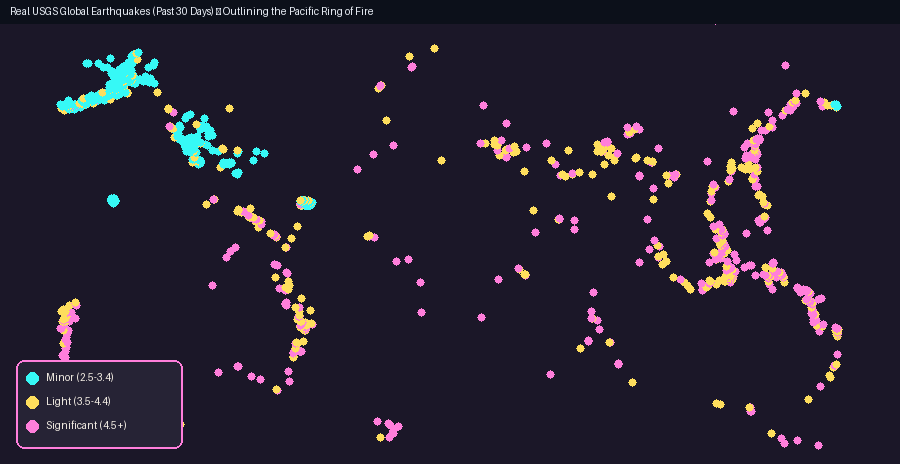

[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


Fiji (+178 E) to Tonga (-175 W):
  Naive flat Euclidean math :  353.0 degrees (WRONG — wraps the long way around Earth!)
  vksp.haversine_distance() :  805.8 km      (TRUE great-circle distance across the Pacific!)

Computed 1,763 GPU Morton Z-order spatial keys in 17.88 ms (min=103920, max=16463287)


In [2]:
# 1. Render Global Seismic Map colored by magnitude tier
mags_list = df["mag"].to_list()
mag_tier = vnp.array([0 if m < 3.5 else (1 if m < 4.5 else 2) for m in mags_list])
lon_lat = vnp.column_stack([df["longitude"]._data, df["latitude"]._data])
display(vkvis.render_embedding(
    lon_lat, labels=mag_tier,
    palette=["#36f9f6", "#fede5d", "#ff7edb"],
    class_names=["Minor (2.5-3.4)", "Light (3.5-4.4)", "Significant (4.5+)"],
    legend_loc="lower left", background="#1b1728", width=900, height=440, point_size=4,
    title="Real USGS Global Earthquakes (Past 30 Days) — Outlining the Pacific Ring of Fire",
))

# 2. Prove the Antimeridian Trap: Fiji (+178 E) vs Tonga (-175 W)
flat_deg = math.hypot(178.0 - (-175.0), -18.0 - (-21.0))
true_km = float(vksp.haversine_distance(vnp.array([178.0]), vnp.array([-18.0]), -175.0, -21.0, unit="km")[0])
print(f"Fiji (+178 E) to Tonga (-175 W):")
print(f"  Naive flat Euclidean math : {flat_deg:6.1f} degrees (WRONG — wraps the long way around Earth!)")
print(f"  vksp.haversine_distance() : {true_km:6.1f} km      (TRUE great-circle distance across the Pacific!)")

# 3. GPU Morton Z-Order Spatial Index (interleaves X/Y bits so nearby places get nearby 1D keys!)
t0 = time.perf_counter()
morton_codes = vksp.morton_encode(df["longitude"], df["latitude"])
dt_morton = (time.perf_counter() - t0) * 1000.0
order = vnp.argsort(morton_codes)
print(f"\nComputed {len(morton_codes):,} GPU Morton Z-order spatial keys in {dt_morton:.2f} ms (min={int(morton_codes[int(order[0])])}, max={int(morton_codes[int(order[-1])])})")


### Step 2 · Discovering Tectonic Fault Lines Automatically with GPU `DBSCAN`

Unlike `KMeans` (which forces every point into a round ball and makes you guess `k` up front), **`vklearn.DBSCAN`** grows clusters along curved, snake-like shapes (like tectonic trenches!) and marks isolated intraplate quakes as **noise (`-1`)**.

To avoid the ±180° Pacific wrap, we first project every `(lat, lon)` onto the **3D unit sphere**:
$$(x, y, z) = (\cos\phi\cos\lambda,\; \cos\phi\sin\lambda,\; \sin\phi)$$
On the unit sphere, Fiji and Tonga are right next to each other!


GPU DBSCAN discovered 7 tectonic seismic belts + 150 isolated intraplate quakes in 114.3 ms!
  Belt #1:  915 quakes (e.g. 19 km NNE of Willow, Alaska)
  Belt #2:  355 quakes (e.g. 211 km WSW of Tual, Indonesia)
  Belt #3:  149 quakes (e.g. 24 km SSW of Boca de Yuma, Dominican Republic)
  Belt #4:   79 quakes (e.g. 64 km W of San Juan, Peru)
  Belt #5:   60 quakes (e.g. 69 km SSW of Shihezi, China)


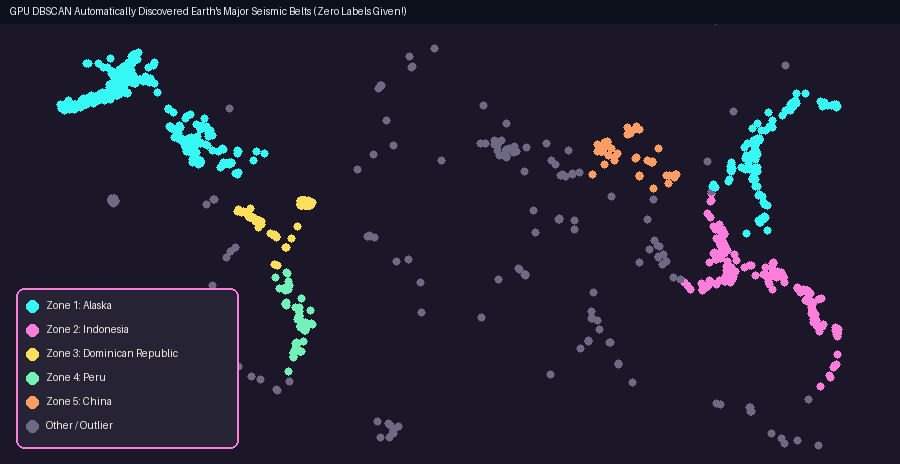

In [3]:
def lonlat_to_sphere3d(lon, lat):
    """Project (longitude, latitude) degrees onto the 3D unit sphere (no +-180 wrap!)."""
    rad = math.pi / 180.0
    lon_r, lat_r = lon * rad, lat * rad
    clat = vnp.cos(lat_r)
    return vnp.column_stack([clat * vnp.cos(lon_r), clat * vnp.sin(lon_r), vnp.sin(lat_r)])

xyz = lonlat_to_sphere3d(df["longitude"]._data, df["latitude"]._data)

t0 = time.perf_counter()
db = vkl.DBSCAN(eps=0.14, min_samples=15).fit(xyz)
dt_db = (time.perf_counter() - t0) * 1000.0
db_labels = db.labels_.tolist()

# Keep top 5 largest seismic belts + group smaller belts & intraplate outliers
from collections import Counter
counts = Counter(l for l in db_labels if l >= 0)
top5_ids = [cid for cid, _ in counts.most_common(5)]
id_to_plot = {cid: idx for idx, cid in enumerate(top5_ids)}
n_clusters = len(counts)
n_noise = sum(1 for l in db_labels if l == -1)

print(f"GPU DBSCAN discovered {n_clusters} tectonic seismic belts + {n_noise} isolated intraplate quakes in {dt_db:.1f} ms!")
top5_names = []
places_list = df["place"].to_list()
for rank, cid in enumerate(top5_ids, 1):
    # Pick a representative region name from the cluster
    sample_place = next(places_list[i] for i, l in enumerate(db_labels) if l == cid)
    region = sample_place.split(",")[-1].strip()[:18]
    top5_names.append(f"Zone {rank}: {region}")
    print(f"  Belt #{rank}: {counts[cid]:4d} quakes (e.g. {sample_place})")

plot_lbl = vnp.array([id_to_plot.get(l, 5) for l in db_labels])
display(vkvis.render_embedding(
    lon_lat, labels=plot_lbl,
    palette=["#36f9f6", "#ff7edb", "#fede5d", "#72f1b8", "#ff9e64", "#6e6a86"],
    class_names=top5_names + ["Other / Outlier"],
    legend_loc="lower left", background="#1b1728", width=900, height=440, point_size=4,
    title="GPU DBSCAN Automatically Discovered Earth's Major Seismic Belts (Zero Labels Given!)",
))


### Step 3 · Geospatial Feature Engineering & Classical ML Leaderboard

Now let's predict whether an earthquake is **Significant (`mag >= 4.5`)** from its **location, depth, and seismic neighborhood** — strictly splitting into **80% Train / 20% Test** *before* computing any spatial neighbor stats (zero data leakage!).

What features do real geospatial ML pipelines build?
- **3D Unit-Sphere Coordinates `(x, y, z)`** (eliminates the ±180° discontinuity)
- **Depth & `log1p(depth)`** (deep subduction-zone quakes behave very differently from shallow crustal quakes!)
- **Haversine Distance to 6 Major Tectonic Trenches** (Japan, Tonga/Kermadec, Peru-Chile, Aleutian, Sunda/Indonesia, San Andreas)
- **Local Seismic Density & Neighbor Depth** (distance to 5th-nearest training quake & mean neighbor depth via GPU `vklearn.NearestNeighbors` — purely from location, zero target leakage!)


Engineered 16 Geospatial features on Vulkan GPU: ['sphere_x', 'sphere_y', 'sphere_z', 'depth_km', 'log_depth', 'abs_lat', 'rms', 'dist_japan_trench', 'dist_tonga_trench', 'dist_andes_trench', 'dist_aleutian_arc', 'dist_sunda_trench', 'dist_san_andreas', 'dist_nearest_trench', 'local_density_dist', 'local_mean_depth']



Classical Geospatial Model               |  Test Acc |     Time
-----------------------------------------------------------------
1. Raw (lon, lat, depth) LogisticReg     |   77.90% |   41.6 ms
2. Engineered Geo + GPU KNN (k=11)       |   81.59% |   43.7 ms
3. Engineered Geo + RandomForest (40)    |   83.00% | 1287.3 ms
4. Engineered Geo + GradientBoosting     |   83.29% | 1554.8 ms

Top-5 GradientBoosting Geo Features: dist_san_andreas (65.6%), rms (5.8%), abs_lat (5.4%), depth_km (4.8%), local_mean_depth (4.1%)


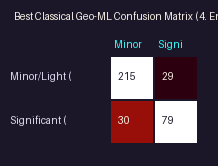

In [4]:
# Leak-free 80/20 split (exact same random_state=42 split will be used in Part 2!)
idx_all = vnp.arange(len(df))
tr_idx, te_idx = vkl.train_test_split(idx_all, test_size=0.2, random_state=42)
tr_list, te_list = [int(i) for i in tr_idx.tolist()], [int(i) for i in te_idx.tolist()]

lon_all, lat_all = df["longitude"]._data, df["latitude"]._data
dep_all, rms_all = df["depth"]._data, df["rms"]._data
y_all = (df["mag"]._data >= 4.5)

# Raw baseline features: just (longitude, latitude, depth)
X_raw = vnp.column_stack([lon_all, lat_all, dep_all])
X_raw_tr, X_raw_te = vnp.take(X_raw, tr_idx, axis=0), vnp.take(X_raw, te_idx, axis=0)
y_tr, y_te = vnp.take(y_all, tr_idx, axis=0), vnp.take(y_all, te_idx, axis=0)

# Major tectonic trench / fault reference points (lon, lat)
TRENCHES = [
    ("japan_trench",   143.0,  38.0),
    ("tonga_trench",  -173.5, -21.0),
    ("andes_trench",   -71.5, -22.0),
    ("aleutian_arc",  -165.0,  53.0),
    ("sunda_trench",   105.0,  -7.0),
    ("san_andreas",   -119.0,  35.5),
]

# Fit train-only spatial neighbor lookup on 3D unit sphere (zero leakage!)
xyz_tr, xyz_te = vnp.take(xyz, tr_idx, axis=0), vnp.take(xyz, te_idx, axis=0)
dep_tr = vnp.take(dep_all, tr_idx, axis=0)
nn_geo = vkl.NearestNeighbors(n_neighbors=8).fit(xyz_tr)

def build_geo_features(idx_vec, is_train=False):
    lon_s = vnp.take(lon_all, idx_vec, axis=0)
    lat_s = vnp.take(lat_all, idx_vec, axis=0)
    dep_s = vnp.take(dep_all, idx_vec, axis=0)
    rms_s = vnp.take(rms_all, idx_vec, axis=0)
    xyz_s = vnp.take(xyz, idx_vec, axis=0)

    cols = {
        "sphere_x": xyz_s[:, 0],
        "sphere_y": xyz_s[:, 1],
        "sphere_z": xyz_s[:, 2],
        "depth_km": dep_s,
        "log_depth": vnp.log1p(dep_s),
        "abs_lat": vnp.abs(lat_s),
        "rms": rms_s,
    }
    trench_dists = []
    for tname, tlon, tlat in TRENCHES:
        d_km = vksp.haversine_distance(lon_s, lat_s, tlon, tlat, unit="km")
        cols[f"dist_{tname}"] = d_km / 1000.0
        trench_dists.append(d_km)

    min_trench = trench_dists[0]
    for d_km in trench_dists[1:]:
        min_trench = vnp.minimum(min_trench, d_km)
    cols["dist_nearest_trench"] = min_trench / 1000.0

    # Local seismic density & neighborhood depth (skip self if train!)
    dists, inds = nn_geo.kneighbors(xyz_s)
    start_k = 1 if is_train else 0
    k_use = 5
    d_slice = dists[:, start_k : start_k + k_use]
    i_slice = inds[:, start_k : start_k + k_use]
    cols["local_density_dist"] = vnp.mean(d_slice, axis=1)
    nb_dep = vnp.take(dep_tr, i_slice.reshape(-1)).reshape(i_slice.shape)
    cols["local_mean_depth"] = vnp.mean(nb_dep, axis=1)
    return vpd.DataFrame(cols)

X_geo_tr = build_geo_features(tr_idx, is_train=True)
X_geo_te = build_geo_features(te_idx, is_train=False)
print(f"Engineered {len(X_geo_tr.columns)} Geospatial features on Vulkan GPU: {list(X_geo_tr.columns)}")

# Race 4 Classical Geospatial ML Models
models = []

t0 = time.perf_counter()
m_raw = vkl.Pipeline([("sc", vkl.StandardScaler()), ("lr", vkl.LogisticRegression(C=1.0, max_iter=60))]).fit(X_raw_tr, y_tr)
p_raw = m_raw.predict(X_raw_te)
models.append(("1. Raw (lon, lat, depth) LogisticReg", float(vkl.accuracy_score(y_te, p_raw)), (time.perf_counter()-t0)*1000, p_raw))

t0 = time.perf_counter()
m_knn = vkl.Pipeline([("sc", vkl.StandardScaler()), ("knn", vkl.KNeighborsClassifier(n_neighbors=11))]).fit(X_geo_tr, y_tr)
p_knn = m_knn.predict(X_geo_te)
models.append(("2. Engineered Geo + GPU KNN (k=11)", float(vkl.accuracy_score(y_te, p_knn)), (time.perf_counter()-t0)*1000, p_knn))

t0 = time.perf_counter()
m_rf = vkl.RandomForestClassifier(n_estimators=40, max_depth=8, max_features="sqrt", random_state=42).fit(X_geo_tr, y_tr)
p_rf = m_rf.predict(X_geo_te)
models.append(("3. Engineered Geo + RandomForest (40)", float(vkl.accuracy_score(y_te, p_rf)), (time.perf_counter()-t0)*1000, p_rf))

t0 = time.perf_counter()
m_gb = vkl.GradientBoostingClassifier(n_estimators=60, learning_rate=0.1, max_depth=4, random_state=42).fit(X_geo_tr, y_tr)
p_gb = m_gb.predict(X_geo_te)
models.append(("4. Engineered Geo + GradientBoosting", float(vkl.accuracy_score(y_te, p_gb)), (time.perf_counter()-t0)*1000, p_gb))

print(f"\n{'Classical Geospatial Model':40s} | {'Test Acc':>9s} | {'Time':>8s}")
print("-" * 65)
for name, acc, dt, _ in models:
    print(f"{name:40s} | {acc:8.2%} | {dt:6.1f} ms")

best_name, best_acc, _, best_pred = max(models, key=lambda r: r[1])
top_imp = sorted(zip(list(X_geo_tr.columns), m_gb.feature_importances_.tolist()), key=lambda x: -x[1])[:5]
print("\nTop-5 GradientBoosting Geo Features:", ", ".join(f"{n} ({v:.1%})" for n, v in top_imp))
display(vkplot.confusion_matrix(
    y_te, best_pred, ["Minor/Light (<4.5)", "Significant (4.5+)"],
    title=f"Best Classical Geo-ML Confusion Matrix ({best_name}: {best_acc:.2%})",
))


---
### Geospatial Part 1 Takeaways
- **Spherical geometry matters:** Projecting `(lon, lat)` onto the 3D unit sphere and measuring **Haversine** distances eliminates the ±180° Pacific wrap and latitude distortion.
- **GPU `DBSCAN`** automatically traced Earth's major tectonic belts directly from 3D coordinates without a single label.
- **Next Up → Geospatial · Part 2 (`GeoSeismicNet`):** Can a Deep Neural Network with **Multi-Scale Fourier Geo-Encodings** (the exact coordinate encoding used in Google's SatCLIP & Uber's Geo-Transformers) beat Classical Geospatial ML on this exact same split?
